### The modes that grow: `im_cc3m_2x4k_e20`

**Reading the eigenvalue plot.** Each dot is one mode of K, placed at its eigenvalue `a + ib`. Since K is applied once, from block 6 to block 12:
- distance from the origin, `|λ|`, is the mode's gain. Inside the unit circle the mode's coefficient shrinks, outside it grows;
- the angle is how far the mode's 2D coefficient rotates. On the real axis (`b = 0`) it doesn't rotate at all;
- dot size is how often TopK keeps the mode. It says nothing about how large the coefficients are when kept.

Most modes sit inside the circle, but a cluster of almost purely real modes sits near `λ ≈ 1.35`, kept rarely. This notebook asks what those modes are: which images use them, how much of the latent they hold, and what removing them does. We look at ImageNet validation and a sample of CC3M, since the model was trained on both.

In [1]:
import copy
import io
import os
import sys
import tarfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
from datasets import load_dataset
from dotenv import load_dotenv
from PIL import Image
from safetensors.torch import load_file

sys.path.insert(0, "../scripts/tokae")
from train import JordanKoopmanAutoencoder, encode_pairs

load_dotenv("../.env")
torch.set_grad_enabled(False)
torch.manual_seed(0)
torch.set_num_threads(16)
pd.set_option("display.width", 200)

NAME = "im_cc3m_2x4k_e20"
CKPT_DIR = Path("/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/ckpt_live")
BIG = 1.0  # a mode is "big" if |eigenvalue| is above this
NUM_CC3M = 10_000
NUM_SHOWN = 6

BLUE, ORANGE, MUTED, INK = "#2a78d6", "#eb6834", "#898781", "#52514e"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": MUTED,
        "axes.labelcolor": INK,
        "xtick.color": MUTED,
        "ytick.color": MUTED,
        "axes.grid": True,
        "grid.color": "#e8e7e3",
        "grid.linewidth": 0.6,
        "legend.frameon": False,
    }
)

/tmp/claude-1001/-home-dunstan-git-koopmann/0bba89b8-c8c4-41c4-a0d8-5b331c6750fd/scratchpad/venv/lib/python3.11/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


##### Model, CLIP and data

In [2]:
root = Path(os.getenv("DATASETS_CACHE"))
stats = torch.load(CKPT_DIR / f"{NAME}_stats.pt")
mean, std = stats["mean"].expand(2, -1), stats["std"].expand(2, -1)

val = torch.load(root / "imagenet" / "clip_cls_patch_std_ViT-B-32_val_blocks_5_11.pt")
val_x, val_y = (val["states"].float() - mean) / std, val["labels"]
images = load_dataset("ILSVRC/imagenet-1k", split="validation", cache_dir=os.getenv("DATASETS_CACHE"))
class_names = open_clip.IMAGENET_CLASSNAMES

kae = JordanKoopmanAutoencoder(
    top_k=256,
    shared_modes=stats.get("shared_modes", False),
    in_features=val_x.shape[-1],
    latent_features=2049,
    hidden_config=stats.get("hidden_config", [2048]),
    bias=True,
    batchnorm=False,
    nonlinearity="leaky_relu",
)
kae.load_state_dict(load_file(CKPT_DIR / f"{NAME}.safetensors"))
kae.eval()

# shape: [modes]. Mode 0 is the real eigenvalue, mode m > 0 is the block on latent coordinates 2m - 1 and 2m
eigenvalues = torch.cat([kae.real_eigenvalue.to(torch.cfloat), torch.complex(kae.block_real, kae.block_imag)])
big = eigenvalues.abs() > BIG
print(f"{int(big.sum())} of {len(eigenvalues)} modes have |eigenvalue| > {BIG}; |eigenvalue| median {eigenvalues.abs().median():.2f}")

clip, _, preprocess = open_clip.create_model_and_transforms(
    "ViT-B-32", pretrained="openai", force_quick_gelu=True, cache_dir=f"{os.getenv('HF_HOME')}/open_clip"
)
clip.eval()
head = torch.load(Path(os.getenv("WEIGHTS_CACHE")) / "tokae" / "zero_shot_head_ViT-B-32.pt")
width = clip.visual.ln_post.normalized_shape[0]


def embed(states):
    cls = states[..., :width] * std[1, :width] + mean[1, :width]
    out = clip.visual.ln_post(cls) @ clip.visual.proj
    return out / out.norm(dim=-1, keepdim=True)


def classify(states):
    return (embed(states) @ head).argmax(dim=-1)


def predict(model, start):
    return torch.cat([model.decode(model.koopman_forward(model.encode(batch), 1)) for batch in start.split(5_000)])


def scale_modes(modes, alpha):
    """A copy of the KAE whose K has these modes' eigenvalues multiplied by alpha (one number, or one per mode)."""

    edited = copy.deepcopy(kae)
    alpha = torch.as_tensor(alpha, dtype=torch.float).expand(len(modes))
    for mode, a in zip(modes, alpha.tolist()):
        if mode == 0:
            edited.real_eigenvalue.mul_(a)
        else:
            edited.block_real[mode - 1].mul_(a)
            edited.block_imag[mode - 1].mul_(a)
    return edited

/home/dunstan/git/koopmann/koopmann/models/autoencoder.py:48: UserWarning: The latent dimension 2049 should probably be larger than the input dimension 2304!
  warnings.warn(


55 of 1025 modes have |eigenvalue| > 1.0; |eigenvalue| median 0.47


CC3M has no cached copy we can index back to images, so we run CLIP on the first images of the first shards, the same way the training cache was built.

In [3]:
def get_states(pixels):
    """Unstandardized states after blocks 6 and 12: CLS, patch mean and patch std."""

    states = []

    def keep(_, __, output):
        patches = output[:, 1:]
        states.append(torch.cat([output[:, 0], patches.mean(dim=1), patches.std(dim=1)], dim=-1))

    hooks = [clip.visual.transformer.resblocks[block].register_forward_hook(keep) for block in stats["blocks"]]
    clip.encode_image(pixels)
    for hook in hooks:
        hook.remove()
    return torch.stack(states, dim=1)


cc3m_bytes = []
for shard in sorted((root / "cc3m-wds").glob("cc3m-train-*.tar")):
    with tarfile.open(shard) as tar:
        for member in tar:
            if member.name.endswith(".jpg"):
                cc3m_bytes.append(tar.extractfile(member).read())
                if len(cc3m_bytes) == NUM_CC3M:
                    break
    if len(cc3m_bytes) == NUM_CC3M:
        break


def open_cc3m(index):
    return Image.open(io.BytesIO(cc3m_bytes[index])).convert("RGB")


cc3m_raw = torch.cat(
    [get_states(torch.stack([preprocess(open_cc3m(i)) for i in range(start, min(start + 250, NUM_CC3M))])) for start in range(0, NUM_CC3M, 250)]
)
cc3m_x = (cc3m_raw - mean) / std
print(f"{len(cc3m_x)} CC3M images; mean state norm after blocks 6 and 12: CC3M {cc3m_raw.norm(dim=-1).mean(0).tolist()}, ImageNet {val['states'].float().norm(dim=-1).mean(0).tolist()}")

10000 CC3M images; mean state norm after blocks 6 and 12: CC3M [6.7069525718688965, 18.27914047241211], ImageNet [6.767035007476807, 18.274696350097656]


##### Where the latent energy is

For each image and mode, the coefficient's size at block 6 and block 12 (with shared modes, both ends keep the same modes). Energy is the squared size. Below, the same spectrum three ways: dot size by how often the mode is kept (the plot in the modes notebook), then by the mode's share of all block-12 latent energy, on ImageNet and on CC3M. Big modes are orange.

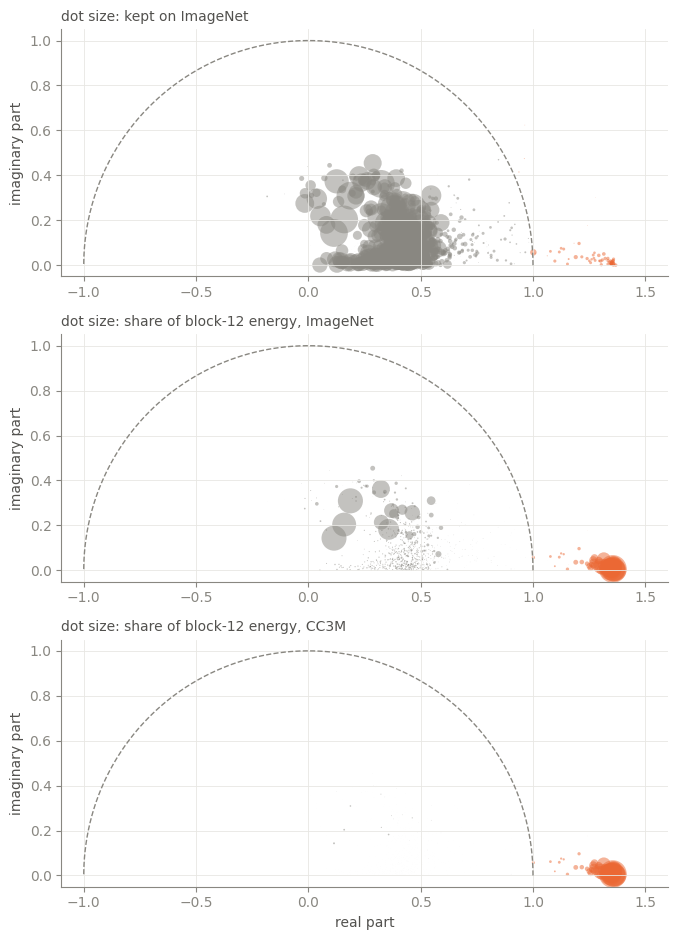

,ImageNet,CC3M
big modes' share of block-12 energy,0.630,0.997
images with any big mode kept,0.366,0.567
"big modes kept per image, median",0.000,1.000


In [4]:
def get_sizes(x):
    """Each mode's coefficient size at both ends, as [images, 2, modes]."""

    phi = torch.cat([encode_pairs(kae, batch) for batch in x.split(5_000)])
    return torch.cat([phi[..., :1].abs(), phi[..., 1:].unflatten(-1, (-1, 2)).norm(dim=-1)], dim=-1)


sizes = {"ImageNet": get_sizes(val_x), "CC3M": get_sizes(cc3m_x)}
usage = {source: (s[:, 0] > 0).double().mean(dim=0) for source, s in sizes.items()}
energy_share = {source: s[:, 1].pow(2).sum(dim=0) / s[:, 1].pow(2).sum() for source, s in sizes.items()}

panels = [
    ("kept on ImageNet", usage["ImageNet"]),
    ("share of block-12 energy, ImageNet", energy_share["ImageNet"]),
    ("share of block-12 energy, CC3M", energy_share["CC3M"]),
]
fig, axes = plt.subplots(3, 1, figsize=(9, 9.5))
circle = np.exp(1j * np.linspace(0, np.pi, 200))
for ax, (title, weight) in zip(axes, panels):
    ax.plot(circle.real, circle.imag, color=MUTED, lw=1, ls="--")
    scale = 400 / weight.max().item()
    for mask, color in [(~big, MUTED), (big, ORANGE)]:
        ax.scatter(eigenvalues.real[mask].numpy(), eigenvalues.imag[mask].abs().numpy(), s=(scale * weight[mask]).numpy(), color=color, alpha=0.5, lw=0)
    ax.set_xlim(-1.1, 1.6)
    ax.set_ylim(-0.05, 1.05)
    ax.set_aspect("equal")
    ax.set_ylabel("imaginary part")
    ax.set_title(f"dot size: {title}", loc="left", color=INK, fontsize=10)
axes[-1].set_xlabel("real part")
fig.tight_layout()
plt.show()

pd.DataFrame(
    {
        source: {
            "big modes' share of block-12 energy": energy_share[source][big].sum().item(),
            "images with any big mode kept": (sizes[source][:, 0][:, big] > 0).any(dim=1).double().mean().item(),
            "big modes kept per image, median": (sizes[source][:, 0][:, big] > 0).sum(dim=1).double().median().item(),
        }
        for source in sizes
    }
).round(3)

##### The big modes one by one

For each big mode: how often it is kept on each dataset, its share of block-12 energy, and how much its coefficient actually grows on the images where it is kept (median of `|z₁₂| / |z₆|`), against `|λ|`. With shared modes, block 12's coefficient comes from encoding the real block 12, so the measured gain can differ from `|λ|`; R² says how well `λ·z₆` predicts `z₁₂` for the mode.

In [5]:
def mode_fit(source, mode):
    """Measured gain and R² of λ·z₆ against z₁₂ for one mode, over images where it is kept."""

    x = val_x if source == "ImageNet" else cc3m_x
    on = sizes[source][:, 0, mode] > 0
    if on.sum() < 5:
        return float("nan"), float("nan")
    phi = encode_pairs(kae, x[on])
    if mode == 0:
        z6, z12 = phi[:, 0, 0].to(torch.cfloat), phi[:, 1, 0].to(torch.cfloat)
    else:
        z6 = torch.complex(phi[:, 0, 2 * mode - 1], phi[:, 0, 2 * mode])
        z12 = torch.complex(phi[:, 1, 2 * mode - 1], phi[:, 1, 2 * mode])
    gain = (z12.abs() / z6.abs().clamp_min(1e-12)).median().item()
    r2 = 1 - ((z12 - eigenvalues[mode] * z6).abs().pow(2).sum() / (z12 - z12.mean()).abs().pow(2).sum()).item()
    return gain, r2


rows = []
for mode in big.nonzero()[:, 0].tolist():
    row = {"mode": mode, "λ": f"{eigenvalues[mode].real:.2f}{eigenvalues[mode].imag:+.2f}i", "|λ|": eigenvalues[mode].abs().item()}
    for source in sizes:
        gain, r2 = mode_fit(source, mode)
        row[f"kept, {source}"] = usage[source][mode].item()
        row[f"energy share, {source}"] = energy_share[source][mode].item()
        row[f"gain, {source}"] = gain
        row[f"R², {source}"] = r2
    rows.append(row)
big_table = pd.DataFrame(rows).set_index("mode").sort_values("energy share, CC3M", ascending=False)
big_table.round(3)

,λ,|λ|,"kept, ImageNet","energy share, ImageNet","gain, ImageNet","R², ImageNet","kept, CC3M","energy share, CC3M","gain, CC3M","R², CC3M"
mode,,,,,,,,,,
227,1.36-0.01i,1.355,0.033,0.060,0.990,0.942,0.166,0.094,1.336,0.995
969,1.36+0.01i,1.356,0.028,0.046,0.907,0.942,0.147,0.071,1.343,0.995
216,1.36+0.00i,1.360,0.012,0.040,1.009,0.938,0.154,0.065,1.347,0.995
175,1.35-0.01i,1.346,0.013,0.038,1.053,0.938,0.136,0.059,1.342,0.995
990,1.37-0.00i,1.368,0.015,0.035,0.978,0.940,0.143,0.055,1.356,0.995
955,1.35+0.01i,1.349,0.013,0.027,1.018,0.939,0.136,0.044,1.351,0.994
131,1.35-0.01i,1.354,0.014,0.026,0.953,0.940,0.132,0.041,1.350,0.994
246,1.36-0.02i,1.358,0.013,0.024,0.925,0.940,0.132,0.039,1.357,0.994
106,1.35-0.01i,1.350,0.021,0.024,0.796,0.940,0.137,0.038,1.345,0.994


##### Which images carry them?

Each image's total block-12 latent energy against the share of it held by big modes. If the big modes are what inflates the latents, the images with huge energy should be the ones whose energy is almost all in big modes.

ImageNet: top 1% of images by energy hold 0.63 of it, and big modes hold 0.00 of their energy (median); other images: 0.000
CC3M: top 1% of images by energy hold 0.52 of it, and big modes hold 1.00 of their energy (median); other images: 0.001


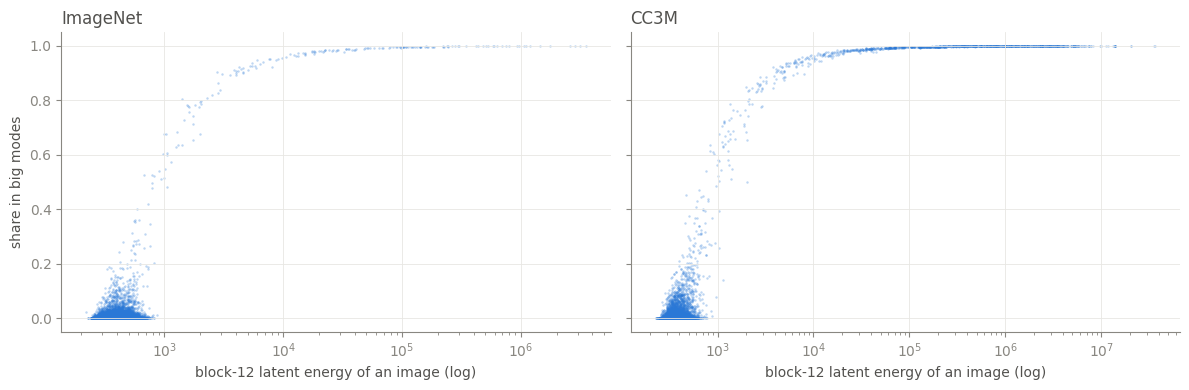

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, (source, s) in zip(axes, sizes.items()):
    energy = s[:, 1].pow(2).sum(dim=1)
    share = s[:, 1][:, big].pow(2).sum(dim=1) / energy
    ax.scatter(energy.numpy(), share.numpy(), s=3, color=BLUE, alpha=0.3, lw=0)
    ax.set_xscale("log")
    ax.set_xlabel("block-12 latent energy of an image (log)")
    ax.set_title(source, loc="left", color=INK)
    top = energy >= energy.quantile(0.99)
    print(f"{source}: top 1% of images by energy hold {energy[top].sum() / energy.sum():.2f} of it, and big modes hold {share[top].median():.2f} of their energy (median); other images: {share[~top].median():.3f}")
axes[0].set_ylabel("share in big modes")
fig.tight_layout()
plt.show()

##### What they fire on

The big modes with the largest energy share on CC3M. For each, its 8 strongest images (by coefficient size at block 6), first from ImageNet validation, then from the CC3M sample.

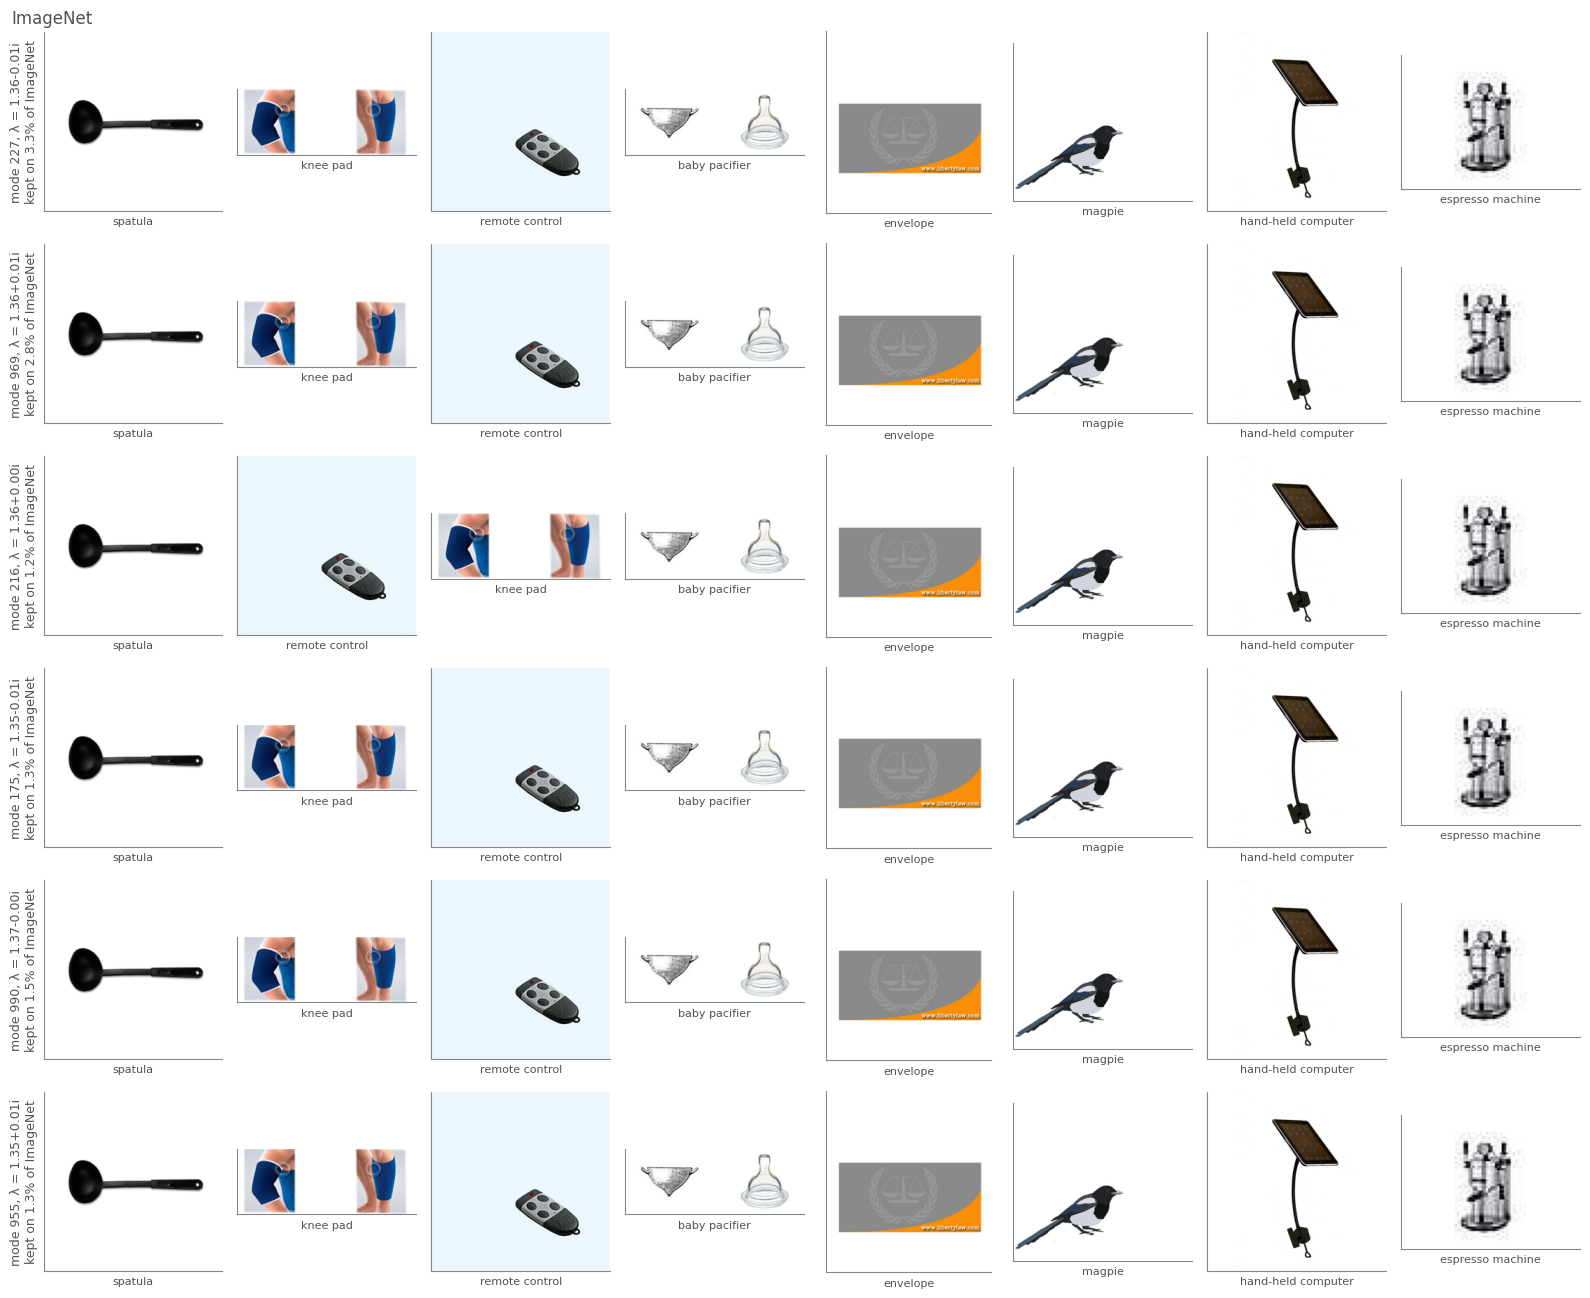

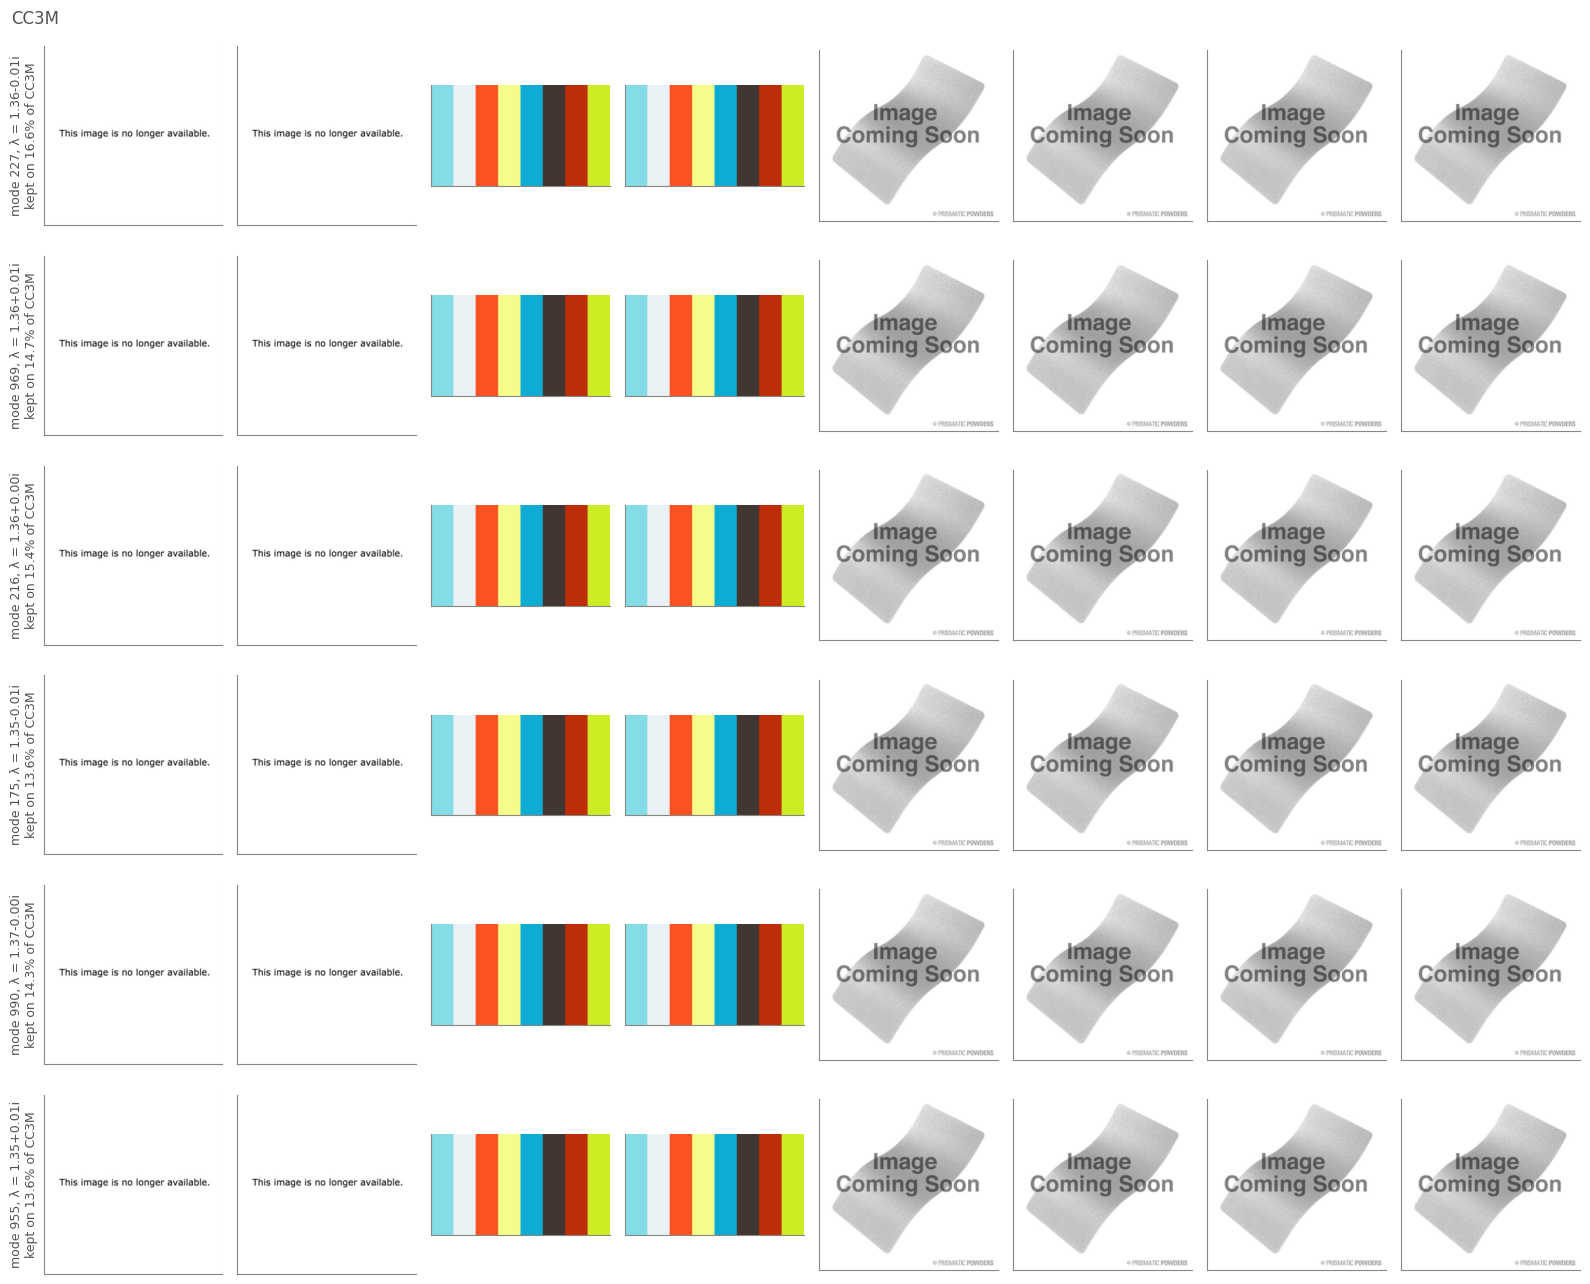

In [7]:
shown_modes = big_table.index[:NUM_SHOWN].tolist()


def show(modes, source):
    fig, axes = plt.subplots(len(modes), 8, figsize=(16, 2.2 * len(modes)), squeeze=False)
    for row, mode in zip(axes, modes):
        for ax, index in zip(row, sizes[source][:, 0, mode].topk(8).indices.tolist()):
            image = images[index]["image"].convert("RGB") if source == "ImageNet" else open_cc3m(index)
            image.thumbnail((256, 256))
            ax.imshow(np.asarray(image))
            ax.set_xticks([])
            ax.set_yticks([])
            ax.grid(False)
            if source == "ImageNet":
                ax.set_xlabel(class_names[val_y[index]][:22], fontsize=8, color=INK)
        row[0].set_ylabel(
            f"mode {mode}, λ = {eigenvalues[mode].real:.2f}{eigenvalues[mode].imag:+.2f}i\nkept on {usage[source][mode]:.1%} of {source}",
            fontsize=9,
            color=INK,
        )
    fig.suptitle(source, x=0.01, ha="left", color=INK)
    fig.tight_layout()
    plt.show()


show(shown_modes, "ImageNet")
show(shown_modes, "CC3M")

##### What they do for the prediction

We change all big modes at once and score the prediction with CLIP's zero-shot classifier, on all of ImageNet validation and on the images that keep at least one big mode. Capping sets each big mode's `|λ|` to 1 (no growth, same rotation); removing sets it to 0. We also compare the size of the predicted CLS token with the real one, to see whether the big modes carry the growth in the state's norm from block 6 to block 12.

In [8]:
big_modes = big.nonzero()[:, 0].tolist()
any_big = (sizes["ImageNet"][:, 0][:, big] > 0).any(dim=1)
true_answers = classify(val_x[:, 1])
true_norm = (val_x[:, 1, :width] * std[1, :width] + mean[1, :width]).norm(dim=-1)

rows = {}
for label, model in [
    ("as trained", kae),
    ("big modes capped at |λ| = 1", scale_modes(big_modes, 1 / eigenvalues[big].abs())),
    ("big modes removed", scale_modes(big_modes, 0.0)),
]:
    prediction = predict(model, val_x[:, 0])
    answers = classify(prediction)
    norm = (prediction[:, :width] * std[1, :width] + mean[1, :width]).norm(dim=-1)
    rows[label] = {
        "zero-shot, all": (answers == val_y).double().mean().item(),
        "zero-shot, with a big mode": (answers[any_big] == val_y[any_big]).double().mean().item(),
        "zero-shot, without": (answers[~any_big] == val_y[~any_big]).double().mean().item(),
        "agrees with CLIP, with a big mode": (answers[any_big] == true_answers[any_big]).double().mean().item(),
        "CLS norm / true, with a big mode": (norm[any_big] / true_norm[any_big]).median().item(),
        "CLS norm / true, without": (norm[~any_big] / true_norm[~any_big]).median().item(),
    }
print(f"{int(any_big.sum())} of {len(any_big)} ImageNet validation images keep at least one big mode")
pd.DataFrame(rows).T.round(3)

18321 of 50000 ImageNet validation images keep at least one big mode


,"zero-shot, all","zero-shot, with a big mode","zero-shot, without","agrees with CLIP, with a big mode","CLS norm / true, with a big mode","CLS norm / true, without"
as trained,0.507,0.529,0.494,0.629,0.884,0.885
big modes capped at |λ| = 1,0.507,0.529,0.494,0.629,0.883,0.885
big modes removed,0.507,0.529,0.494,0.628,0.883,0.885
